In [2]:
#  Imports
import os
import json
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from tqdm import tqdm
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, Subset
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import precision_score, recall_score, f1_score, classification_report
import timm


In [3]:
#  Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)


Device: cuda


In [4]:
#  Paths
train_path = r"C:\\Users\\STUDENT\\Downloads\\brainmri\\archive\\Training_256x256"

In [5]:
#  Transforms
def get_transforms():
    train_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(),
        transforms.RandomRotation(10),
        transforms.ColorJitter(),
        transforms.ToTensor(),
        transforms.Normalize([0.5]*3, [0.5]*3)
    ])
    test_transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.5]*3, [0.5]*3)
    ])
    return train_transform, test_transform


In [6]:
#  Model Creation
def create_model(lr, wd):
    model = timm.create_model('densenet121', pretrained=True, num_classes=4)
    model.to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1)
    criterion = nn.CrossEntropyLoss()
    return model, optimizer, scheduler, criterion

In [7]:
#  Training Function
def train_one_fold(model, optimizer, scheduler, criterion, train_loader, val_loader, patience=3):
    best_val_acc = 0
    best_model = model.state_dict()
    counter = 0
    all_preds_fold, all_labels_fold = [], []

    train_accuracies, val_accuracies = [], []
    train_losses, val_losses = [], []

    for epoch in range(10):
        model.train()
        correct, total, epoch_loss = 0, 0, 0.0
        for imgs, labels in tqdm(train_loader, desc=f"Epoch {epoch+1} [Train]", leave=False):
            imgs, labels = imgs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            epoch_loss += loss.item()

        train_acc = 100 * correct / total
        train_accuracies.append(train_acc)
        train_losses.append(epoch_loss / len(train_loader))

        model.eval()
        correct, total, val_loss = 0, 0, 0.0
        fold_preds, fold_labels = [], []

        with torch.no_grad():
            for imgs, labels in tqdm(val_loader, desc=f"Epoch {epoch+1} [Val]", leave=False):
                imgs, labels = imgs.to(device), labels.to(device)
                outputs = model(imgs)
                loss = criterion(outputs, labels)
                _, preds = torch.max(outputs, 1)
                correct += (preds == labels).sum().item()
                total += labels.size(0)
                val_loss += loss.item()
                fold_preds.extend(preds.cpu().numpy())
                fold_labels.extend(labels.cpu().numpy())

        val_acc = 100 * correct / total
        val_accuracies.append(val_acc)
        val_losses.append(val_loss / len(val_loader))

        print(f"\u2192 Epoch {epoch+1}: Train Acc = {train_acc:.2f}%, Val Acc = {val_acc:.2f}%")

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_model = model.state_dict()
            all_preds_fold = fold_preds
            all_labels_fold = fold_labels
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                print("\u23F9\ufe0f Early stopping triggered.")
                break

        scheduler.step()

    model.load_state_dict(best_model)
    return model, best_val_acc, train_accuracies, val_accuracies, train_losses, val_losses, all_preds_fold, all_labels_fold

In [8]:
#  Plot Function
def plot_and_save_curves(mean_train_acc, mean_val_acc, mean_train_loss, mean_val_loss, lr, wd):
    epochs = range(1, len(mean_train_acc) + 1)
    plt.figure(figsize=(8, 5))
    plt.plot(epochs, mean_train_acc, label='Mean Train Accuracy', marker='o')
    plt.plot(epochs, mean_val_acc, label='Mean Val Accuracy', marker='o')
    plt.title('DenseNet121 - Mean Accuracy per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Accuracy (%)')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"densenet121_accuracy_curve_lr{lr}_wd{wd}.png")
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, mean_train_loss, label='Mean Train Loss', marker='o')
    plt.plot(epochs, mean_val_loss, label='Mean Val Loss', marker='o')
    plt.title('DenseNet121 - Mean Loss per Epoch')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.grid(True)
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"densenet121_loss_curve_lr{lr}_wd{wd}.png")
    plt.show()


Tuning - LR: 0.0001, WD: 0.0001

Fold 1/5


→ Epoch 1: Train Acc = 88.31%, Val Acc = 95.98%


→ Epoch 2: Train Acc = 97.42%, Val Acc = 97.55%


→ Epoch 3: Train Acc = 99.17%, Val Acc = 98.16%


→ Epoch 4: Train Acc = 99.06%, Val Acc = 97.90%


...

→ Epoch 1: Train Acc = 88.16%, Val Acc = 96.41%


→ Epoch 2: Train Acc = 97.22%, Val Acc = 97.81%


→ Epoch 3: Train Acc = 99.15%, Val Acc = 96.50%


→ Epoch 4: Train Acc = 98.86%, Val Acc = 97.55%


→ Epoch 5: Train Acc = 99.63%, Val Acc = 97.72%
⏹️ Early stopping triggered.


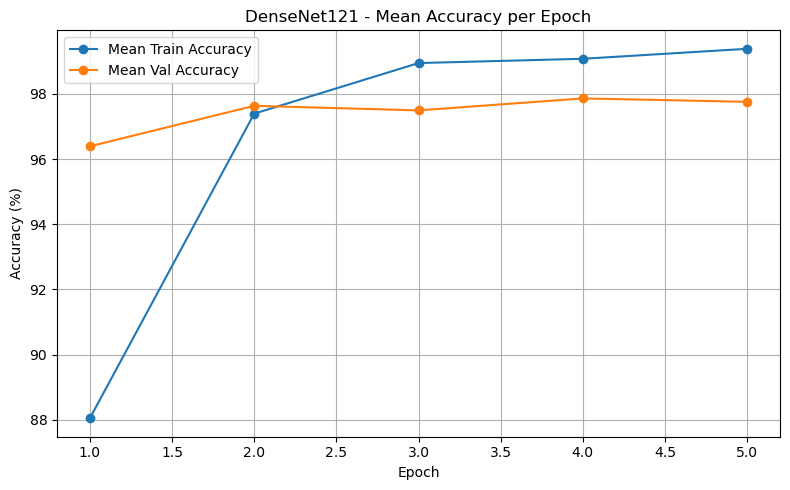

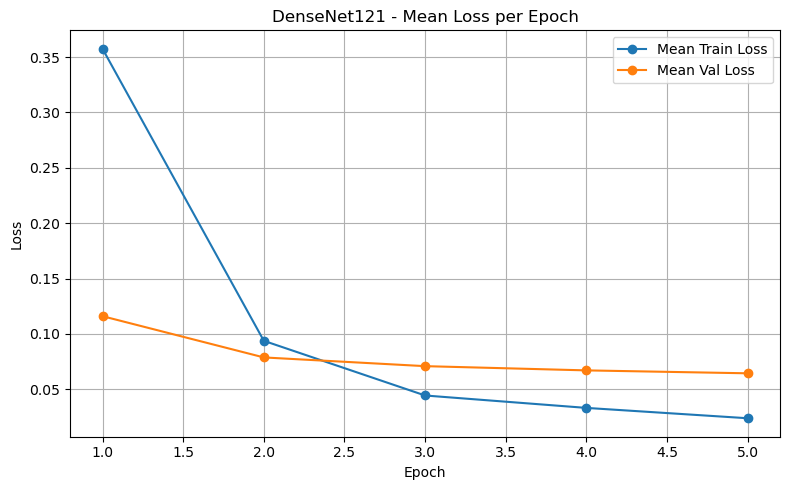


🢾 Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      0.99      0.99      1321
  meningioma       0.98      0.98      0.98      1339
     notumor       0.99      0.99      0.99      1595
   pituitary       0.99      0.99      0.99      1457

    accuracy                           0.99      5712
   macro avg       0.99      0.99      0.99      5712
weighted avg       0.99      0.99      0.99      5712


Tuning - LR: 0.0001, WD: 1e-05

Fold 1/5


→ Epoch 1: Train Acc = 88.38%, Val Acc = 96.76%


→ Epoch 2: Train Acc = 97.15%, Val Acc = 98.69%


→ Epoch 3: Train Acc = 98.64%, Val Acc = 98.43%


→ Epoch 4: Train Acc = 99.30%, Val Acc = 98.34%


...

→ Epoch 6: Train Acc = 99.80%, Val Acc = 98.07%


→ Epoch 7: Train Acc = 99.82%, Val Acc = 98.42%


→ Epoch 8: Train Acc = 99.98%, Val Acc = 98.51%


→ Epoch 9: Train Acc = 99.91%, Val Acc = 98.34%


→ Epoch 10: Train Acc = 100.00%, Val Acc = 98.34%


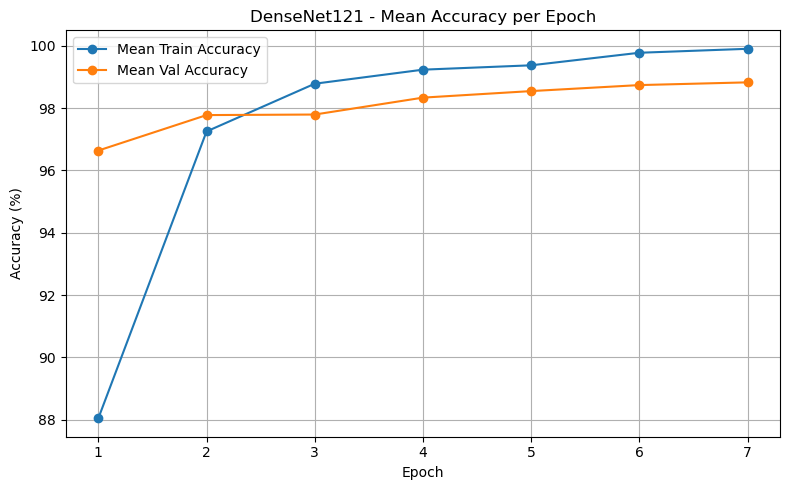

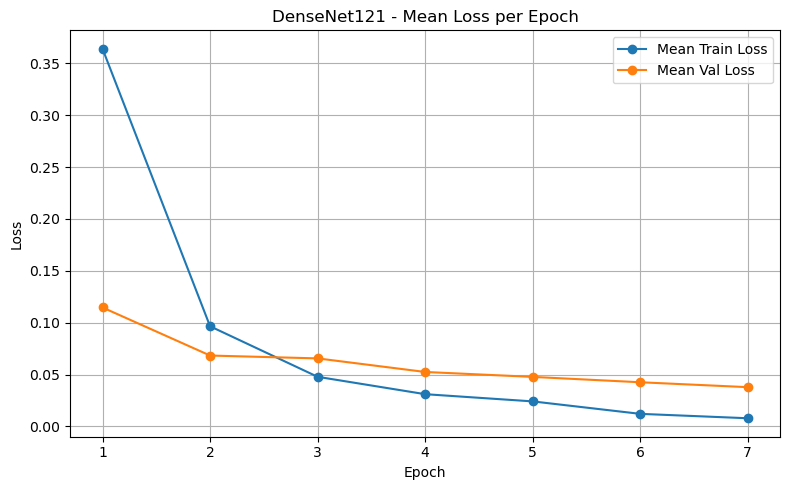


🢾 Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      0.98      0.99      1321
  meningioma       0.97      0.98      0.98      1339
     notumor       1.00      1.00      1.00      1595
   pituitary       0.99      0.99      0.99      1457

    accuracy                           0.99      5712
   macro avg       0.99      0.99      0.99      5712
weighted avg       0.99      0.99      0.99      5712


Tuning - LR: 0.0003, WD: 0.0001

Fold 1/5


→ Epoch 1: Train Acc = 90.57%, Val Acc = 95.28%


→ Epoch 2: Train Acc = 96.54%, Val Acc = 97.38%


→ Epoch 3: Train Acc = 97.90%, Val Acc = 95.71%


→ Epoch 4: Train Acc = 98.66%, Val Acc = 98.16%


...

→ Epoch 6: Train Acc = 99.58%, Val Acc = 98.16%


→ Epoch 7: Train Acc = 99.89%, Val Acc = 98.25%


→ Epoch 8: Train Acc = 99.93%, Val Acc = 98.16%


→ Epoch 9: Train Acc = 99.98%, Val Acc = 98.25%


→ Epoch 10: Train Acc = 99.96%, Val Acc = 98.34%


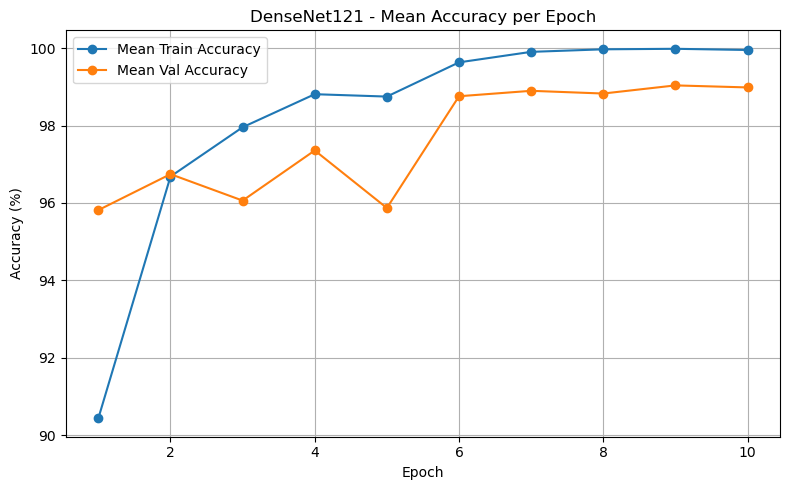

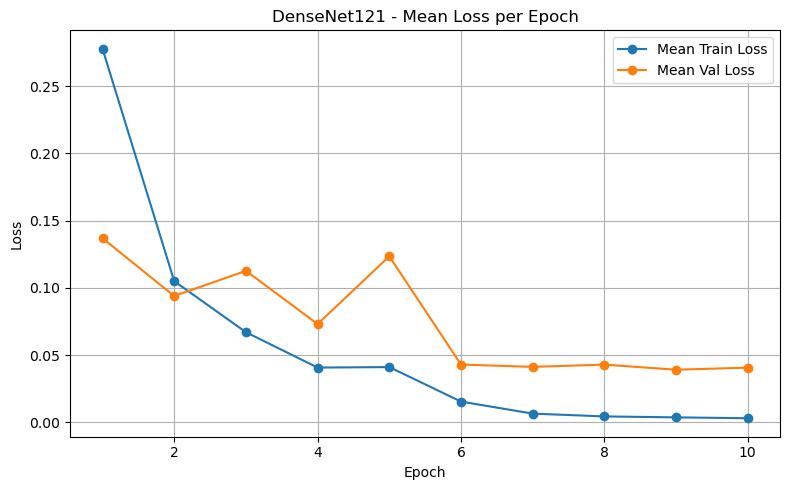


🢾 Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      1.00      0.99      1321
  meningioma       0.98      0.98      0.98      1339
     notumor       0.99      0.99      0.99      1595
   pituitary       0.99      0.99      0.99      1457

    accuracy                           0.99      5712
   macro avg       0.99      0.99      0.99      5712
weighted avg       0.99      0.99      0.99      5712


Tuning - LR: 0.0003, WD: 1e-05

Fold 1/5


→ Epoch 1: Train Acc = 90.92%, Val Acc = 96.94%


→ Epoch 2: Train Acc = 96.70%, Val Acc = 97.46%


→ Epoch 3: Train Acc = 97.90%, Val Acc = 96.68%


→ Epoch 4: Train Acc = 98.71%, Val Acc = 95.89%


...

→ Epoch 6: Train Acc = 99.72%, Val Acc = 98.42%


→ Epoch 7: Train Acc = 99.89%, Val Acc = 98.86%


→ Epoch 8: Train Acc = 99.93%, Val Acc = 98.69%


→ Epoch 9: Train Acc = 99.96%, Val Acc = 98.77%


→ Epoch 10: Train Acc = 99.98%, Val Acc = 98.69%
⏹️ Early stopping triggered.


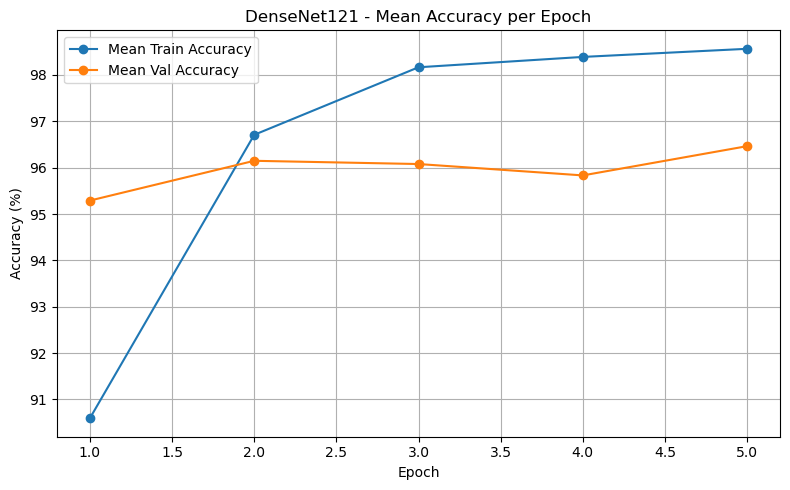

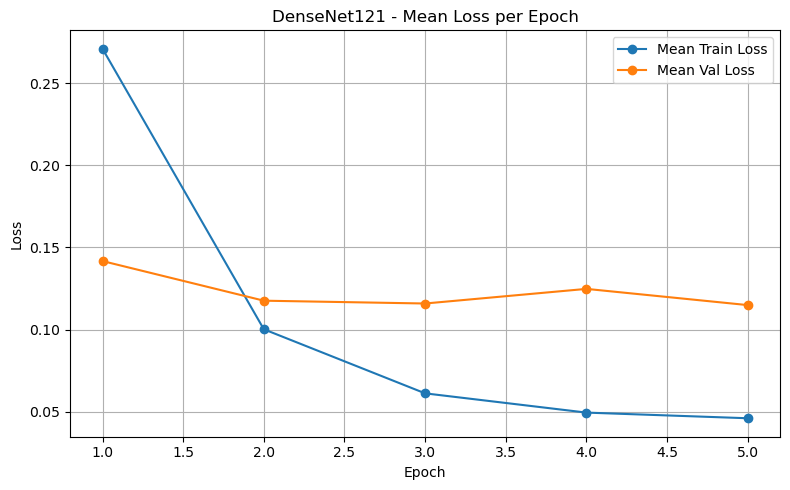


🢾 Classification Report:
              precision    recall  f1-score   support

      glioma       0.99      0.99      0.99      1321
  meningioma       0.97      0.98      0.97      1339
     notumor       0.99      0.99      0.99      1595
   pituitary       0.99      0.99      0.99      1457

    accuracy                           0.99      5712
   macro avg       0.99      0.99      0.99      5712
weighted avg       0.99      0.99      0.99      5712



In [11]:
#  Main Cross-Validation Tuning
best_score = 0
best_config = {}
all_results = []

train_transform, test_transform = get_transforms()
dataset = datasets.ImageFolder(train_path, transform=train_transform)
targets = [label for _, label in dataset.samples]
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
learning_rates = [1e-4, 3e-4]
weight_decays = [1e-4, 1e-5]
batch_size = 16

for lr in learning_rates:
    for wd in weight_decays:
        print(f"\n\033[94mTuning - LR: {lr}, WD: {wd}\033[0m")
        fold_accs = []
        all_preds, all_labels = [], []
        all_train_accuracies = []
        all_val_accuracies = []
        all_train_losses = []
        all_val_losses = []

        for fold, (train_idx, val_idx) in enumerate(skf.split(np.zeros(len(targets)), targets)):
            print(f"\n\033[95mFold {fold+1}/5\033[0m")
            train_subset = Subset(dataset, train_idx)
            val_subset = Subset(dataset, val_idx)
            val_subset.dataset.transform = test_transform

            train_loader = DataLoader(train_subset, batch_size=batch_size, shuffle=True, num_workers=2, pin_memory=True)
            val_loader = DataLoader(val_subset, batch_size=batch_size, shuffle=False, num_workers=2, pin_memory=True)

            model, optimizer, scheduler, criterion = create_model(lr, wd)
            model, best_val_acc, train_accs, val_accs, train_los, val_los, preds, labels = train_one_fold(
                model, optimizer, scheduler, criterion, train_loader, val_loader
            )

            fold_accs.append(best_val_acc)
            all_preds.extend(preds)
            all_labels.extend(labels)
            all_train_accuracies.append(train_accs)
            all_val_accuracies.append(val_accs)
            all_train_losses.append(train_los)
            all_val_losses.append(val_los)

        precision = precision_score(all_labels, all_preds, average='macro')
        recall = recall_score(all_labels, all_preds, average='macro')
        f1 = f1_score(all_labels, all_preds, average='macro')
        mean_acc = np.mean(fold_accs)
        params = sum(p.numel() for p in model.parameters() if p.requires_grad) / 1e6

        metrics_cv = {
            "mode": "with_cv",
            "learning_rate": lr,
            "weight_decay": wd,
            "accuracy": round(mean_acc, 2),
            "precision": round(precision * 100, 2),
            "recall": round(recall * 100, 2),
            "f1_score": round(f1 * 100, 2),
            "parameters_million": round(params, 2)
        }
        # Track result
        result = {
            "learning_rate": lr,
            "weight_decay": wd,
            "accuracy": round(mean_acc, 2),
            "precision": round(precision * 100, 2),
            "recall": round(recall * 100, 2),
            "f1_score": round(f1 * 100, 2),
            "parameters_million": round(params, 2)
        }
        all_results.append(result)
        
        # Save to JSON
        with open(f"metrics_densenet_cv_lr{lr}_wd{wd}.json", "w") as f:
            json.dump(result, f, indent=4)
        
        # Update best config
        if mean_acc > best_score:
            best_score = mean_acc
            best_config = result

        from numpy import nanmean

        #  Get max epoch length
        max_len = max(len(fold) for fold in all_train_accuracies)
        
        #  Pad all fold lists with np.nan
        def pad_list(lst, max_len):
            return lst + [np.nan] * (max_len - len(lst))
        
        all_train_accuracies = [pad_list(fold, max_len) for fold in all_train_accuracies]
        all_val_accuracies   = [pad_list(fold, max_len) for fold in all_val_accuracies]
        all_train_losses     = [pad_list(fold, max_len) for fold in all_train_losses]
        all_val_losses       = [pad_list(fold, max_len) for fold in all_val_losses]
        
        #  Compute means safely
        mean_train_acc  = nanmean(all_train_accuracies, axis=0)
        mean_val_acc    = nanmean(all_val_accuracies, axis=0)
        mean_train_loss = nanmean(all_train_losses, axis=0)
        mean_val_loss   = nanmean(all_val_losses, axis=0)


        file_name = f"metrics_densenet121_cv_lr{lr}_wd{wd}.json"
        with open(file_name, "w") as f:
            json.dump(metrics_cv, f, indent=4)

        mean_train_acc = np.mean(all_train_accuracies, axis=0)
        mean_val_acc = np.mean(all_val_accuracies, axis=0)
        mean_train_loss = np.mean(all_train_losses, axis=0)
        mean_val_loss = np.mean(all_val_losses, axis=0)

        plot_and_save_curves(mean_train_acc, mean_val_acc, mean_train_loss, mean_val_loss, lr, wd)

        print("\n\U0001F8BE Classification Report:")
        print(classification_report(all_labels, all_preds, target_names=dataset.classes))


In [12]:
print("\n Best Hyperparameter Configuration for DenseNet:")
print(json.dumps(best_config, indent=4))

with open("densenet_cv_all_results.json", "w") as f:
    json.dump(all_results, f, indent=4)



 Best Hyperparameter Configuration for DenseNet:
{
    "learning_rate": 0.0003,
    "weight_decay": 0.0001,
    "accuracy": 99.05,
    "precision": 99.03,
    "recall": 99.03,
    "f1_score": 99.03,
    "parameters_million": 6.96
}
